<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab9_1_ANN_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes Neuronales Artificiales (ANN)
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 75 minutos

Referencia: [scikit-learn Neural Network](https://scikit-learn.org/stable/modules/neural_networks_supervised.html) | [TensorFlow/Keras](https://www.tensorflow.org/guide/keras)

---

### Objetivos de aprendizaje

1. Describir la estructura de una neurona artificial, una capa y una red feedforward.
2. Definir funciones de activación y explicar por qué las no lineales son esenciales.
3. Explicar la propagación hacia adelante y la retropropagación conceptualmente.
4. Entrenar una ANN simple en `scikit-learn` y Keras para clasificación y regresión ambiental.
5. Reconocer el sobreajuste y aplicar técnicas de regularización.

## 1. ¿Por Qué Redes Neuronales?

Hemos cubierto un poderoso conjunto de herramientas ML. Pero cada algoritmo tiene una limitación fundamental:

| Algoritmo | Limitación |
|-----------|------------|
| Regresión Lineal | No aprende patrones no lineales sin ingeniería de características manual |
| SVM RBF | Lento en datasets grandes; elección de kernel es manual |
| Random Forest / XGBoost | Dificultad con datos no estructurados (imágenes, secuencias) |
| KNN | Lento en predicción; falla en alta dimensión |

**Las redes neuronales** son diferentes. Con suficientes neuronas y datos, pueden **aprender cualquier función** — incluyendo mapeos no lineales de alta dimensión que serían imposibles de diseñar manualmente. Esta propiedad se llama el **teorema de aproximación universal**.

### Aplicaciones en el Perú donde las ANN destacan
- **Relleno de datos faltantes** en estaciones SENAMHI (muchas variables interactuando)
- **Predicción de caudales** en cuencas amazónicas con datos de lluvia satelital
- **Estimación de biomasa** desde múltiples variables de teledetección
- **Predicción de calidad del aire** en Lima con datos meteorológicos horarios
- **Bases** para CNN (imágenes) y LSTM (series de tiempo) — próximos Labs

## 2. La Neurona Artificial

Una neurona artificial imita el proceso biológico:

1. **Recibe entradas** $x_1, x_2, \ldots, x_M$
2. **Calcula una suma ponderada** $z = w_1 x_1 + w_2 x_2 + \ldots + w_M x_M + b$ (los pesos son como las fuerzas sinápticas; $b$ es el sesgo)
3. **Aplica una función de activación** $a = f(z)$ (la decisión de "disparar o no")
4. **Produce la salida** $a$ a la siguiente capa

Una sola neurona artificial con activación sigmoide **es exactamente la regresión logística**. Las redes neuronales generalizan la regresión logística apilando muchas neuronas en capas.

## 3. Funciones de Activación: La Magia No Lineal

Sin funciones de activación no lineales, apilar capas de neuronas solo produciría otra función lineal — no importa cuántas capas. Las funciones de activación son lo que hace que el apilado de capas sea significativo.

| Función | Fórmula | Rango | Cuándo usar |
|---------|---------|-------|-------------|
| **Sigmoide** | $\frac{1}{1+e^{-z}}$ | $(0, 1)$ | Capa de salida para clasificación binaria |
| **Tanh** | $\frac{e^z - e^{-z}}{e^z + e^{-z}}$ | $(-1, 1)$ | Capas ocultas (centrada en 0) |
| **ReLU** | $\max(0, z)$ | $[0, \infty)$ | Opción predeterminada para capas ocultas |
| **Softmax** | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | $(0, 1)$, suma = 1 | Capa de salida para clasificación multi-clase |

**ReLU** (Unidad Lineal Rectificada) es la más usada en la práctica porque es simple, rápida y evita el problema del gradiente desvaneciente.

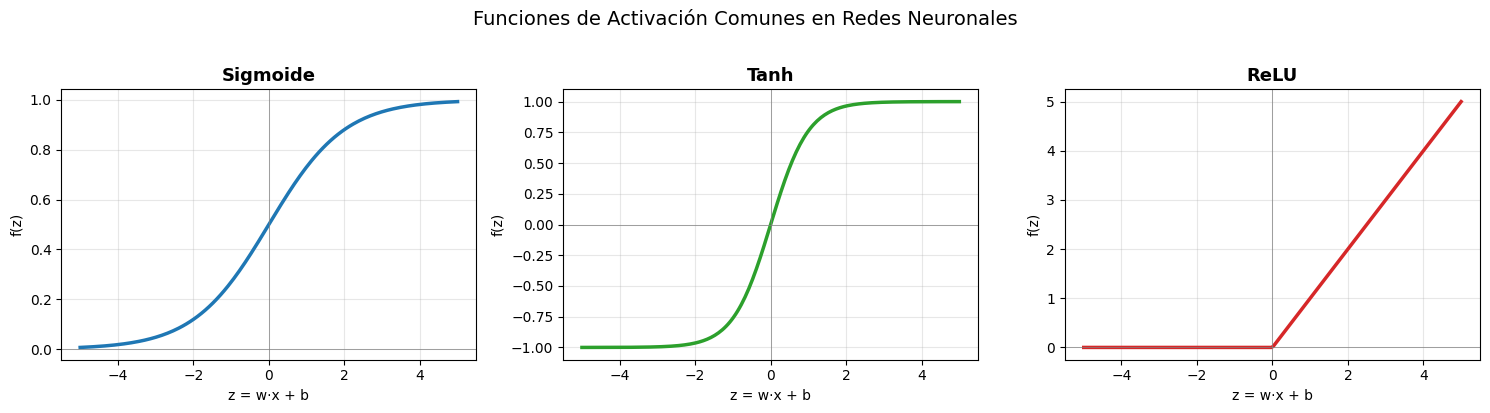

Sin activación no lineal, apilar capas = una sola transformación lineal
→ Equivalente a la regresión lineal, sin importar la profundidad


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-5, 5, 200)

sigmoide = 1 / (1 + np.exp(-z))
tanh     = np.tanh(z)
relu     = np.maximum(0, z)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
titulos = ['Sigmoide', 'Tanh', 'ReLU']
funcs   = [sigmoide, tanh, relu]
colores = ['#1f77b4', '#2ca02c', '#d62728']

for ax, titulo, f, color in zip(ejes, titulos, funcs, colores):
    ax.plot(z, f, color=color, linewidth=2.5)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.set_title(titulo, fontsize=13, fontweight='bold')
    ax.set_xlabel('z = w·x + b')
    ax.set_ylabel('f(z)')
    ax.grid(True, alpha=0.3)

plt.suptitle('Funciones de Activación Comunes en Redes Neuronales', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Sin activación no lineal, apilar capas = una sola transformación lineal")
print("→ Equivalente a la regresión lineal, sin importar la profundidad")

## 4. Arquitectura de Red: Capas y Profundidad

```
Capa de Entrada → Capa(s) Oculta(s) → Capa de Salida
```

- **Capa de entrada:** Una neurona por característica. Sin cómputo.
- **Capa(s) oculta(s):** Donde ocurre el aprendizaje.
- **Capa de salida:** Para clasificación binaria: 1 neurona con sigmoide. Para multi-clase ($C$ clases): $C$ neuronas con softmax. Para regresión: 1 neurona sin activación.

## 5. Propagación hacia Adelante

Para hacer una predicción, los datos fluyen **hacia adelante** a través de las capas:
1. Cada neurona en la capa oculta calcula: $z = \mathbf{w} \cdot \mathbf{x} + b$, luego $a = f(z)$
2. Las activaciones de la capa oculta se convierten en las entradas de la siguiente capa
3. Continúa hasta la capa de salida

In [ ]:
# Propagación hacia adelante manual para una red pequeña
# 2 entradas → 2 neuronas ocultas (ReLU) → 1 salida (sigmoide)

# Entrada: [NDVI, Temperatura] (características estandarizadas)
x = np.array([0.75, -0.5])  # alto NDVI, temperatura baja

# Pesos (normalmente aprendidos; aquí establecidos para demostración)
W1 = np.array([[0.6, -0.4], [0.3, 0.8]])  # pesos de entrada a oculta
b1 = np.array([0.1, -0.2])

W2 = np.array([[0.9], [-0.6]])  # pesos de oculta a salida
b2 = np.array([0.1])

# Capa oculta
z1 = W1 @ x + b1
a1 = np.maximum(0, z1)  # ReLU

# Capa de salida
z2 = W2.T @ a1 + b2
a2 = 1 / (1 + np.exp(-z2))  # Sigmoide

print("Propagación hacia adelante:")
print(f"  Entrada: NDVI=0.75, Temp=-0.5 (estandarizado)")
print(f"  Capa oculta: z1 = {z1}")
print(f"               a1 = ReLU(z1) = {a1}")
print(f"  Capa salida: z2 = {z2}")
print(f"               a2 = Sigmoide(z2) = {a2[0]:.4f}")
print(f"\n  Predicción: P(bosque = 1) = {a2[0]:.4f}")
print(f"  Clasificación: {'Bosque' if a2[0] >= 0.5 else 'No-Bosque'}")

Propagación hacia adelante:
  Entrada: NDVI=0.75, Temp=-0.5 (estandarizado)
  Capa oculta: z1 = [ 0.75  -0.375]
               a1 = ReLU(z1) = [0.75 0.  ]
  Capa salida: z2 = [0.775]
               a2 = Sigmoide(z2) = 0.6846

  Predicción: P(bosque = 1) = 0.6846
  Clasificación: Bosque


## 6. Entrenamiento: Retropropagación y Descenso de Gradiente

El entrenamiento de una red neuronal significa ajustar los pesos para minimizar la pérdida. El algoritmo que hace esto es la **retropropagación** combinada con el **descenso de gradiente**:

1. **Pasada hacia adelante:** Calcular la predicción
2. **Calcular la pérdida:** ¿Qué tan incorrecta es la predicción?
3. **Pasada hacia atrás:** Calcular el **gradiente** de la pérdida respecto a cada peso (usando la regla de la cadena)
4. **Actualizar pesos:** $w_{\text{nuevo}} = w_{\text{viejo}} - \eta \cdot \frac{\partial L}{\partial w}$
5. **Repetir** por muchas iteraciones (**épocas**)

> **No necesitas implementar la retropropagación tú mismo.** `scikit-learn`, TensorFlow y PyTorch calculan todos los gradientes automáticamente.

## 7. ANN en `scikit-learn`: Clasificación

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

# Dataset: clasificar cobertura del suelo peruano
np.random.seed(42)
n_por_clase = 400
agua        = np.random.normal([700, 800, 600, 300, 150, 100], [80]*6, (n_por_clase, 6))
bos_amazon  = np.random.normal([400, 550, 350, 3800, 1600, 700], [80,80,80,400,300,150], (n_por_clase, 6))
cultivos    = np.random.normal([700, 800, 700, 2600, 2100, 1100], [100]*6, (n_por_clase, 6))
urbano      = np.random.normal([1200, 1300, 1400, 1700, 2400, 2100], [200]*6, (n_por_clase, 6))
puna        = np.random.normal([600, 750, 700, 1500, 1200, 800], [100]*6, (n_por_clase, 6))

X_esp = np.vstack([agua, bos_amazon, cultivos, urbano, puna])
y_esp = np.array([0]*n_por_clase + [1]*n_por_clase + [2]*n_por_clase +
                 [3]*n_por_clase + [4]*n_por_clase)
nombres_clases = ['Agua', 'Bosque Amazónico', 'Cultivos', 'Urbano', 'Puna']

# ¡Siempre escalar para redes neuronales!
esc = StandardScaler()
X_e = esc.fit_transform(X_esp)

X_tr, X_te, y_tr, y_te = train_test_split(X_e, y_esp, test_size=0.25, random_state=42)

# Entrenar MLP (Red Neuronal Multicapa)
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),  # 2 capas ocultas: 64 y 32 neuronas
    activation='relu',             # Activación ReLU
    max_iter=500,
    random_state=42,
    learning_rate_init=0.001
)
mlp.fit(X_tr, y_tr)
y_pred = mlp.predict(X_te)

print(f"Arquitectura: {mlp.hidden_layer_sizes}")
print(f"Épocas de entrenamiento: {mlp.n_iter_}")
print(f"Pérdida final: {mlp.loss_:.4f}")
print(f"Exactitud de prueba: {metrics.accuracy_score(y_te, y_pred):.2%}")
print("\nReporte de clasificación:")
print(metrics.classification_report(y_te, y_pred, target_names=nombres_clases))

Arquitectura: (64, 32)
Épocas de entrenamiento: 77
Pérdida final: 0.0019
Exactitud de prueba: 100.00%

Reporte de clasificación:
                  precision    recall  f1-score   support

            Agua       1.00      1.00      1.00       104
Bosque Amazónico       1.00      1.00      1.00       110
        Cultivos       1.00      1.00      1.00        83
          Urbano       1.00      1.00      1.00       100
            Puna       1.00      1.00      1.00       103

        accuracy                           1.00       500
       macro avg       1.00      1.00      1.00       500
    weighted avg       1.00      1.00      1.00       500



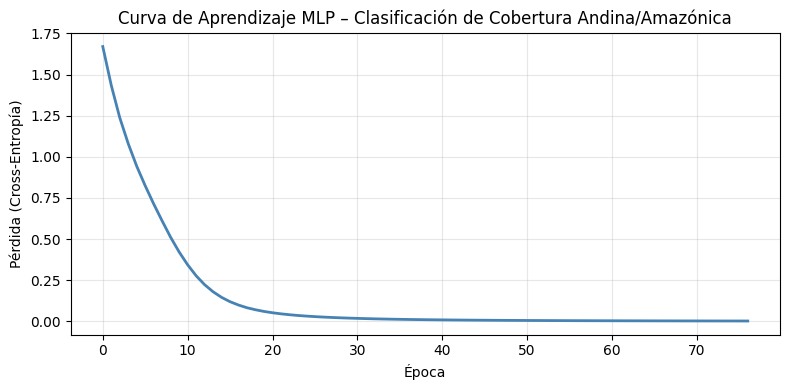

La pérdida cae rápidamente en las primeras épocas, luego se estabiliza.
¡IMPORTANTE: Siempre usar StandardScaler antes de entrenar ANNs!


In [ ]:
# Curva de pérdida durante el entrenamiento
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mlp.loss_curve_, color='steelblue', linewidth=2)
ax.set_xlabel('Época')
ax.set_ylabel('Pérdida (Cross-Entropía)')
ax.set_title('Curva de Aprendizaje MLP – Clasificación de Cobertura Andina/Amazónica')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("La pérdida cae rápidamente en las primeras épocas, luego se estabiliza.")
print("¡IMPORTANTE: Siempre usar StandardScaler antes de entrenar ANNs!")

## 8. ANN para Regresión: Predicción de Caudal

Aplicamos una ANN para predecir el **caudal diario del río Ucayali** desde variables meteorológicas del SENAMHI.

In [ ]:
corte

2250

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Dataset sintético: cuenca del Ucayali (características SENAMHI)
np.random.seed(42)
n_dias = 3000
fechas = np.arange(n_dias)

# Variables meteorológicas
precip_prox_7d = np.convolve(np.random.exponential(8, n_dias), np.ones(7)/7, mode='same')
temp_media     = np.random.normal(27, 3, n_dias)   # Temperatura media diaria (°C)
humedad        = np.random.normal(85, 8, n_dias)    # Humedad relativa (%)
evapotransp    = np.maximum(0, 4 + 0.2*(temp_media-27) - 0.05*humedad)

# Caudal: función no lineal de precipitación acumulada
caudal = (8 * precip_prox_7d**1.2 + 3 * humedad - 20 * evapotransp
          + np.random.normal(0, 50, n_dias))
caudal = np.maximum(caudal, 50)  # m³/s (caudal mínimo)

X_hidro = np.column_stack([precip_prox_7d, temp_media, humedad, evapotransp])
y_caudal = caudal
nombres_hidro = ['Precip_7d (mm)', 'Temp (°C)', 'Humedad (%)', 'ETo (mm/d)']

# División cronológica (importante para series de tiempo!)
corte = int(0.75 * n_dias)
X_tr_h, X_te_h = X_hidro[:corte], X_hidro[corte:]
y_tr_h, y_te_h = y_caudal[:corte], y_caudal[corte:]

esc_h = StandardScaler()
X_tr_he = esc_h.fit_transform(X_tr_h)
X_te_he = esc_h.transform(X_te_h)

# ANN para regresión
mlp_reg = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    max_iter=1000,
    random_state=42,
    learning_rate_init=0.001
)
mlp_reg.fit(X_tr_he, y_tr_h)

y_pred_tr = mlp_reg.predict(X_tr_he)
y_pred_te = mlp_reg.predict(X_te_he)

print(f"R² Entrenamiento: {r2_score(y_tr_h, y_pred_tr):.3f}")
print(f"R² Prueba:        {r2_score(y_te_h, y_pred_te):.3f}")
print(f"RMSE Prueba:      {np.sqrt(mean_squared_error(y_te_h, y_pred_te)):.1f} m³/s")

R² Entrenamiento: 0.552
R² Prueba:        0.534
RMSE Prueba:      49.0 m³/s


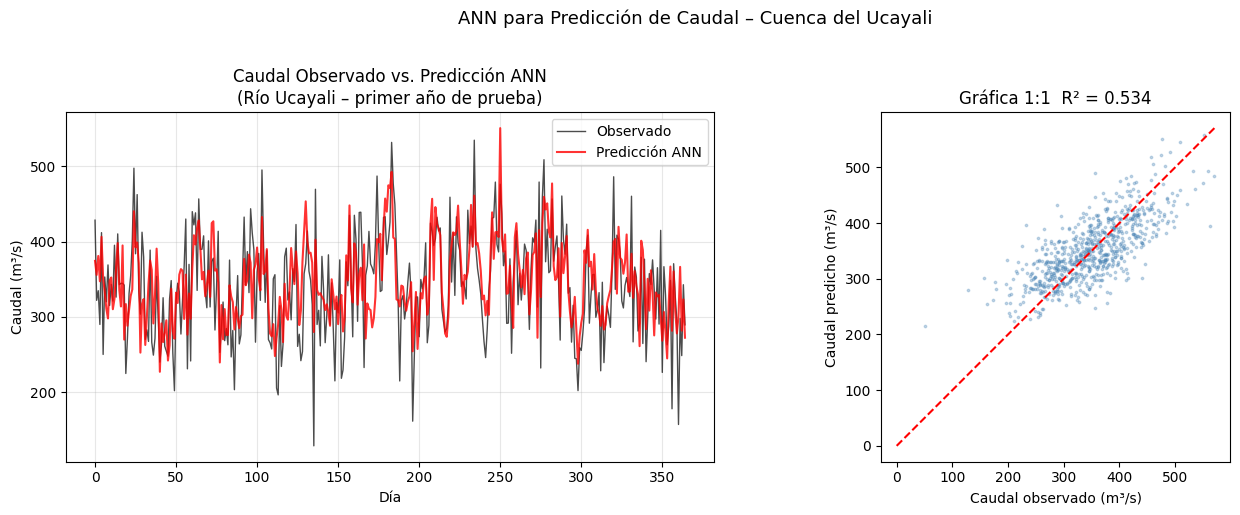

In [ ]:
# Gráficas de validación
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

# Serie de tiempo
dias_prueba = np.arange(len(y_te_h))
ejes[0].plot(dias_prueba[:365], y_te_h[:365], 'k-', linewidth=1, alpha=0.7, label='Observado')
ejes[0].plot(dias_prueba[:365], y_pred_te[:365], 'r-', linewidth=1.5, alpha=0.8, label='Predicción ANN')
ejes[0].set_xlabel('Día')
ejes[0].set_ylabel('Caudal (m³/s)')
ejes[0].set_title('Caudal Observado vs. Predicción ANN\n(Río Ucayali – primer año de prueba)')
ejes[0].legend()
ejes[0].grid(True, alpha=0.3)

# Dispersión 1:1
ejes[1].scatter(y_te_h, y_pred_te, s=3, alpha=0.3, color='steelblue')
max_val = max(y_te_h.max(), y_pred_te.max())
ejes[1].plot([0, max_val], [0, max_val], 'r--', linewidth=1.5)
ejes[1].set_xlabel('Caudal observado (m³/s)')
ejes[1].set_ylabel('Caudal predicho (m³/s)')
ejes[1].set_title(f'Gráfica 1:1  R² = {r2_score(y_te_h, y_pred_te):.3f}')
ejes[1].set_aspect('equal')

plt.suptitle('ANN para Predicción de Caudal – Cuenca del Ucayali', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 9. Sobreajuste y Regularización

Las redes neuronales con muchos parámetros pueden memorizarse los datos de entrenamiento. Estrategias para prevenir sobreajuste:

| Estrategia | Cómo funciona | Parámetro en sklearn |
|------------|--------------|----------------------|
| **Early stopping** | Detener entrenamiento cuando la pérdida de validación se estabiliza | `early_stopping=True` |
| **Regularización L2** | Penalizar pesos grandes | `alpha=0.001` |
| **Reducir arquitectura** | Menos neuronas/capas = menos parámetros | `hidden_layer_sizes` |
| **Dropout** | Apagar aleatoriamente neuronas durante entrenamiento | Solo en Keras |

Épocas usadas (con early stopping): 32
Exactitud de prueba: 99.20%


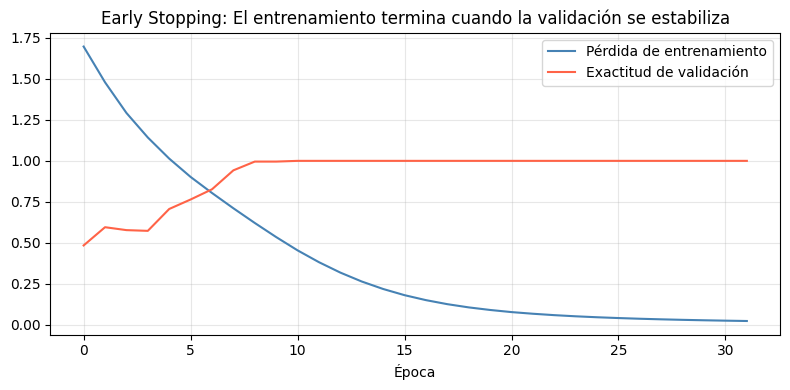

In [ ]:
# Demostrar early stopping
mlp_es = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=1000,
    early_stopping=True,        # Detener cuando la pérdida de validación se estabiliza
    validation_fraction=0.15,   # 15% del entrenamiento para validación
    n_iter_no_change=20,        # Detener si no hay mejora en 20 épocas
    random_state=42
)
mlp_es.fit(X_tr, y_tr)

print(f"Épocas usadas (con early stopping): {mlp_es.n_iter_}")
print(f"Exactitud de prueba: {metrics.accuracy_score(y_te, mlp_es.predict(X_te)):.2%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mlp_es.loss_curve_, label='Pérdida de entrenamiento', color='steelblue')
ax.plot(mlp_es.validation_scores_, label='Exactitud de validación', color='tomato')
ax.set_xlabel('Época')
ax.set_title('Early Stopping: El entrenamiento termina cuando la validación se estabiliza')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Comparación ANN vs. Otros Algoritmos

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

clasificadores = {
    "Regresión Logística":   LogisticRegression(max_iter=300),
    "SVM (RBF)":             SVC(kernel="rbf"),
    "Random Forest (100)":   RandomForestClassifier(100, random_state=42),
    "MLP (64, 32)":          MLPClassifier((64, 32), max_iter=500, random_state=42),
}

print(f"{'Clasificador':<25}  {'Exactitud media':>16}  {'Desv. std':>10}")
print("-" * 55)
for nombre, clf in clasificadores.items():
    puntuaciones = cross_val_score(clf, X_e, y_esp, cv=5)
    print(f"{nombre:<25}  {puntuaciones.mean():>15.3f}  {puntuaciones.std():>10.3f}")

print("\n→ En datasets tabulares pequeños-medianos, RF/XGBoost generalmente")
print("  supera a las ANNs con menos ajuste de hiperparámetros")
print("→ Las ANNs brillan con datos de imágenes o secuencias (siguiente Lab)")

Clasificador                Exactitud media   Desv. std
-------------------------------------------------------
Regresión Logística                  1.000       0.000
SVM (RBF)                            1.000       0.000
Random Forest (100)                  1.000       0.000
MLP (64, 32)                         1.000       0.000

→ En datasets tabulares pequeños-medianos, RF/XGBoost generalmente
  supera a las ANNs con menos ajuste de hiperparámetros
→ Las ANNs brillan con datos de imágenes o secuencias (siguiente Lab)


---
## 🔬 Ejercicio: Red Neuronal para Predecir Calidad del Aire

Usando el dataset de calidad del aire en Lima del Lab 7_3:

1. Entrena un `MLPClassifier` con arquitectura `(32, 16)` para clasificar el ICA
2. Compara la exactitud con Naive Bayes y Random Forest del mismo dataset
3. Activa `early_stopping=True` y observa cuántas épocas se necesitan
4. ¿Por qué el escalado es obligatorio para ANN pero no para Random Forest?

> **Truco del playground:** Puedes experimentar con arquitecturas de redes neuronales de forma visual en: https://playground.tensorflow.org/

In [ ]:
# Recrear dataset de calidad del aire
np.random.seed(42)
n_dias = 365 * 3
pm25_b = np.random.normal(8, 3, n_dias // 3)
pm25_m = np.random.normal(25, 8, n_dias // 3)
pm25_ma = np.random.normal(65, 20, n_dias // 3)
no2_b = np.random.normal(20, 8, n_dias // 3)
no2_m = np.random.normal(60, 15, n_dias // 3)
no2_ma = np.random.normal(120, 30, n_dias // 3)
o3_b = np.random.normal(40, 10, n_dias // 3)
o3_m = np.random.normal(80, 20, n_dias // 3)
o3_ma = np.random.normal(150, 40, n_dias // 3)

X_aire = np.vstack([
    np.column_stack([pm25_b, no2_b, o3_b]),
    np.column_stack([pm25_m, no2_m, o3_m]),
    np.column_stack([pm25_ma, no2_ma, o3_ma])
])
X_aire = np.maximum(X_aire, 0)
y_aire = np.array([0]*(n_dias//3) + [1]*(n_dias//3) + [2]*(n_dias//3))
nombres_ica = ['Bueno', 'Moderado', 'Malo']

# --- Tu código aquí ---
esc_a = StandardScaler()
X_aire_e = esc_a.fit_transform(X_aire)
X_tr_a, X_te_a, y_tr_a, y_te_a = train_test_split(
    X_aire_e, y_aire, test_size=0.25, random_state=42, stratify=y_aire
)

mlp_aire = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    max_iter=500,
    early_stopping=True,
    random_state=42
)
mlp_aire.fit(X_tr_a, y_tr_a)

print(f"ANN – Exactitud: {metrics.accuracy_score(y_te_a, mlp_aire.predict(X_te_a)):.2%}")
print(f"Épocas: {mlp_aire.n_iter_}")
print(metrics.classification_report(y_te_a, mlp_aire.predict(X_te_a), target_names=nombres_ica))

ANN – Exactitud: 96.72%
Épocas: 43
              precision    recall  f1-score   support

       Bueno       0.95      1.00      0.97        91
    Moderado       0.96      0.95      0.95        91
        Malo       1.00      0.96      0.98        92

    accuracy                           0.97       274
   macro avg       0.97      0.97      0.97       274
weighted avg       0.97      0.97      0.97       274



---
## Resumen

| Concepto | Conclusión clave |
|----------|------------------|
| Neurona artificial | Suma ponderada de entradas → función de activación → salida |
| Funciones de activación | Sigmoide, Tanh, ReLU (la más común), Softmax |
| Red feedforward | Entrada → Capas ocultas → Salida; la información fluye en una dirección |
| Propagación hacia adelante | Calcular predicciones pasando entradas por las capas |
| Retropropagación | Calcular gradientes de la pérdida respecto a pesos; propagarlos hacia atrás |
| Escalado de características | **Obligatorio** — usar `StandardScaler` |
| Sobreajuste | Mitigar con early stopping, regularización L2, arquitecturas más pequeñas |
| Cuándo usar ANN | Datasets grandes, patrones complejos, datos no estructurados (imágenes/secuencias) |
| Cuándo NO usar ANN | Datasets tabulares pequeños — preferir Random Forest / XGBoost |

### Hiperparámetros clave

| Parámetro | Qué controla | Valores típicos |
|-----------|--------------|----------------|
| `hidden_layer_sizes` | Arquitectura (neuronas por capa) | `(32,)`, `(64, 32)`, `(128, 64, 32)` |
| `activation` | No linealidad | `'relu'` (predeterminado y recomendado) |
| `learning_rate_init` | Tamaño de paso | 0.001 (predeterminado) |
| `alpha` | Fuerza regularización L2 | 0.0001 (predeterminado) |
| `early_stopping` | Detener cuando la validación se estabiliza | `True` (recomendado) |